# InsureWise AI - Model Training & Benchmark Evaluation
**Notebook:** `05_model_training.ipynb`  
**Project:** InsureWise AI - Explainable ML for Personalized Insurance Premium Prediction  
**Objective:** Systematically train, cross-validate, and evaluate five core regression models (Linear Regression, Ridge Regression, Random Forest Regressor, Gradient Boosting Regressor, and XGBoost Regressor) using scikit-learn `Pipeline` and `ColumnTransformer`. Evaluate final model generalization strictly on an untouched test set without data leakage.

---

## Table of Contents
1. [Environment Setup & Global Configuration](#1.-Environment-Setup-&-Global-Configuration)
2. [Dataset Loading & Leak-Free Train-Test Splitting](#2.-Dataset-Loading-&-Leak-Free-Train-Test-Splitting)
3. [Modular Preprocessing Pipeline Construction](#3.-Modular-Preprocessing-Pipeline-Construction)
4. [Candidate Regression Models & 5-Fold Cross-Validation Framework](#4.-Candidate-Regression-Models-&-5-Fold-Cross-Validation-Framework)
5. [Model Training, CV & Touch-Free Test Set Evaluation](#5.-Model-Training,-CV-&-Touch-Free-Test-Set-Evaluation)
6. [Comprehensive Model Comparison & Overfitting Audit](#6.-Comprehensive-Model-Comparison-&-Overfitting-Audit)
7. [Visual Performance & Error Diagnostics Dashboard](#7.-Visual-Performance-&-Error-Diagnostics-Dashboard)
8. [Residual Distribution & Error Analysis](#8.-Residual-Distribution-&-Error-Analysis)
9. [Holistic Model Selection & Business Trade-Off Discussion](#9.-Holistic-Model-Selection-&-Business-Trade-Off-Discussion)
10. [Reproducible Artifact Export & System Integration](#10.-Reproducible-Artifact-Export-&-System-Integration)
11. [Requirements Compliance Verification Matrix](#11.-Requirements-Compliance-Verification-Matrix)

---
> **Execution Directives:**
> - Primary Dataset: `medical_insurance_cost_dataset_enhanced.csv` (7,500 samples, 22 columns).
> - Train/Test split: 80/20 with `random_state=42`.
> - Preprocessing: scikit-learn `Pipeline` + `ColumnTransformer` with `BloodPressureExtractor`.
> - Strict leakage prevention: Test set kept completely untouched until final evaluation after all CV training.
> - Random state set across all supporting estimators for 100% reproducibility.

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

warnings.filterwarnings('ignore')

# Global Reproducibility & Visualization Options
RANDOM_STATE = 42
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Environment setup completed successfully.")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Joblib version: {joblib.__version__}")


Environment setup completed successfully.
Pandas version: 3.0.6
NumPy version: 2.5.3
Joblib version: 1.6.0


## 2. Dataset Loading & Leak-Free Train-Test Splitting

We load the primary enhanced dataset (`medical_insurance_cost_dataset_enhanced.csv`) containing 7,500 patient records. To strictly prevent **data leakage**, we perform an 80/20 train-test split (`random_state=42`) **prior** to fitting any preprocessing or model transformation.

- **Target Variable ($y$):** `annual_medical_cost_usd`
- **Identifier Column (Dropped):** `customer_id`
- **Training Set:** 6,000 samples (80%)
- **Test Set:** 1,500 samples (20%) - kept strictly untouched during training and cross-validation.

In [2]:
# Define dataset paths with relative and fallback handling
data_path = '../data/raw/medical_insurance_cost_dataset_enhanced.csv'
if not os.path.exists(data_path):
    data_path = '../Data/Raw/medical_insurance_cost_dataset_enhanced.csv'
if not os.path.exists(data_path):
    data_path = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\Data\Raw\medical_insurance_cost_dataset_enhanced.csv'

df = pd.read_csv(data_path)
print(f"Dataset loaded successfully: {df.shape[0]} rows, {df.shape[1]} columns")

target_col = 'annual_medical_cost_usd'
id_col = 'customer_id'

X = df.drop(columns=[target_col, id_col])
y = df[target_col]

# Perform Train-Test Split BEFORE any preprocessing fitting
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training feature set (X_train): {X_train.shape}")
print(f"Testing feature set  (X_test):  {X_test.shape}")
print(f"Training target      (y_train): {y_train.shape}")
print(f"Testing target       (y_test):  {y_test.shape}")


Dataset loaded successfully: 7500 rows, 22 columns
Training feature set (X_train): (6000, 20)
Testing feature set  (X_test):  (1500, 20)
Training target      (y_train): (6000,)
Testing target       (y_test):  (1500,)


## 3. Modular Preprocessing Pipeline Construction

To ensure consistent feature transformation between training, validation, testing, and production FastAPI endpoints:
1. **Custom Transformer (`BloodPressureExtractor`):** Parses string formatted blood pressure (e.g. `'120/80'`) into numeric `systolic_bp` and `diastolic_bp` features, and drops the raw string column.
2. **Numerical Features Sub-pipeline:** Imputes missing values using median (`SimpleImputer`), followed by z-score standardization (`StandardScaler`).
3. **Ordinal Features Sub-pipeline:** Imputes using most frequent values (`SimpleImputer`), followed by ordered numeric encoding (`OrdinalEncoder`).
4. **Nominal Categorical Features Sub-pipeline:** Imputes using most frequent values (`SimpleImputer`), followed by one-hot encoding (`OneHotEncoder(handle_unknown='ignore')`).
5. **Unified `ColumnTransformer`:** Encapsulates all sub-pipelines into a single scikit-learn transformer.

In [3]:
class BloodPressureExtractor(BaseEstimator, TransformerMixin):
    def __init__(self, bp_col='blood_pressure'):
        self.bp_col = bp_col

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_out = X.copy()
        else:
            X_out = pd.DataFrame(X).copy()

        if self.bp_col in X_out.columns:
            split_bp = X_out[self.bp_col].astype(str).str.split('/', expand=True)
            X_out['systolic_bp'] = pd.to_numeric(split_bp[0], errors='coerce').astype('float64')
            X_out['diastolic_bp'] = pd.to_numeric(split_bp[1], errors='coerce').astype('float64')
            X_out = X_out.drop(columns=[self.bp_col])
        return X_out

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            return None
        feature_names = [f for f in input_features if f != self.bp_col]
        feature_names.extend(['systolic_bp', 'diastolic_bp'])
        return np.array(feature_names)

# Programmatic feature identification on training set
bp_transformer = BloodPressureExtractor()
X_train_parsed = bp_transformer.transform(X_train)

num_features = X_train_parsed.select_dtypes(include=['int64', 'float64']).columns.tolist()
ordinal_features = ['exercise_level', 'insurance_plan']
ordinal_category_orders = [
    ['Low', 'Moderate', 'High'],
    ['Basic', 'Standard', 'Premium', 'Gold']
]
categorical_all = X_train_parsed.select_dtypes(include=['object', 'str', 'category']).columns.tolist()
nominal_features = [col for col in categorical_all if col not in ordinal_features]

# Define sub-pipelines
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=ordinal_category_orders,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_features),
        ('ord', ord_pipeline, ordinal_features),
        ('nom', nom_pipeline, nominal_features)
    ],
    remainder='drop'
)

print(f"Numerical features ({len(num_features)}): {num_features}")
print(f"Ordinal features   ({len(ordinal_features)}): {ordinal_features}")
print(f"Nominal features   ({len(nominal_features)}): {nominal_features}")


Numerical features (13): ['age', 'bmi', 'children', 'annual_income_usd', 'chronic_diseases', 'doctor_visits_per_year', 'hospitalizations_last_year', 'alcohol_consumption_per_week', 'cholesterol', 'sleep_hours', 'stress_level', 'systolic_bp', 'diastolic_bp']
Ordinal features   (2): ['exercise_level', 'insurance_plan']
Nominal features   (6): ['gender', 'smoker', 'region', 'occupation', 'diabetes', 'marital_status']


## 4. Candidate Regression Models & 5-Fold Cross-Validation Framework

We evaluate five distinct regression algorithms spanning linear models, bagging ensemble, and boosting ensembles:

1. **Linear Regression:** Baseline unregularized parametric linear model.
2. **Ridge Regression ($L_2$ Regularization):** Parametric linear model with $L_2$ penalty to reduce multi-collinearity sensitivity (`alpha=1.0`).
3. **Random Forest Regressor:** Non-parametric bagging ensemble of 100 decision trees (`n_estimators=100`, `random_state=42`).
4. **Gradient Boosting Regressor:** Sequential boosting ensemble building shallow trees on residual errors (`n_estimators=100`, `random_state=42`).
5. **XGBoost Regressor:** Optimized extreme gradient boosting with regularized tree splits (`n_estimators=100`, `learning_rate=0.1`, `random_state=42`).

### 5-Fold Cross-Validation Protocol
We apply 5-Fold Cross-Validation (`KFold(n_splits=5, shuffle=True, random_state=42)`) **strictly on the training data (`X_train`, `y_train`)**. For each fold, preprocessing is fitted solely on fold-train and evaluated on fold-validation to guarantee zero data leakage.

In [4]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=RANDOM_STATE),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting Regressor': GradientBoostingRegressor(n_estimators=100, random_state=RANDOM_STATE),
    'XGBoost Regressor': XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=RANDOM_STATE, n_jobs=-1)
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'mse': 'neg_mean_squared_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

results = []
fitted_pipelines = {}
predictions_dict = {}

print("Starting 5-Fold Cross-Validation and Touch-Free Evaluation across all 5 models...")

for name, model in models.items():
    print(f"Processing Model: {name}...")
    
    # Construct complete pipeline
    pipeline = Pipeline([
        ('bp_extractor', BloodPressureExtractor()),
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])
    
    # 1. Cross-Validation on Training Data ONLY
    cv_out = cross_validate(pipeline, X_train, y_train, cv=kf, scoring=scoring, return_train_score=True)
    
    cv_train_mae_mean = -cv_out['train_mae'].mean()
    cv_train_mae_std  = cv_out['train_mae'].std()
    cv_val_mae_mean   = -cv_out['test_mae'].mean()
    cv_val_mae_std    = cv_out['test_mae'].std()
    
    cv_train_mse_mean = -cv_out['train_mse'].mean()
    cv_train_mse_std  = cv_out['train_mse'].std()
    cv_val_mse_mean   = -cv_out['test_mse'].mean()
    cv_val_mse_std    = cv_out['test_mse'].std()
    
    cv_train_rmse_mean = -cv_out['train_rmse'].mean()
    cv_train_rmse_std  = cv_out['train_rmse'].std()
    cv_val_rmse_mean   = -cv_out['test_rmse'].mean()
    cv_val_rmse_std    = cv_out['test_rmse'].std()
    
    cv_train_r2_mean = cv_out['train_r2'].mean()
    cv_train_r2_std  = cv_out['train_r2'].std()
    cv_val_r2_mean   = cv_out['test_r2'].mean()
    cv_val_r2_std    = cv_out['test_r2'].std()
    
    # 2. Fit full model pipeline on full X_train
    pipeline.fit(X_train, y_train)
    fitted_pipelines[name] = pipeline
    
    # 3. Evaluate on full X_train and untouched X_test
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)
    
    predictions_dict[name] = {
        'train_pred': y_train_pred,
        'test_pred': y_test_pred
    }
    
    train_mae  = mean_absolute_error(y_train, y_train_pred)
    train_mse  = mean_squared_error(y_train, y_train_pred)
    train_rmse = root_mean_squared_error(y_train, y_train_pred)
    train_r2   = r2_score(y_train, y_train_pred)
    
    test_mae  = mean_absolute_error(y_test, y_test_pred)
    test_mse  = mean_squared_error(y_test, y_test_pred)
    test_rmse = root_mean_squared_error(y_test, y_test_pred)
    test_r2   = r2_score(y_test, y_test_pred)
    
    overfit_gap_r2 = train_r2 - cv_val_r2_mean
    overfit_gap_rmse = cv_val_rmse_mean - train_rmse
    
    results.append({
        'Model': name,
        'CV Train MAE Mean': cv_train_mae_mean,
        'CV Train MAE Std': cv_train_mae_std,
        'CV Val MAE Mean': cv_val_mae_mean,
        'CV Val MAE Std': cv_val_mae_std,
        'Full Train MAE': train_mae,
        'Test MAE': test_mae,
        
        'CV Train MSE Mean': cv_train_mse_mean,
        'CV Train MSE Std': cv_train_mse_std,
        'CV Val MSE Mean': cv_val_mse_mean,
        'CV Val MSE Std': cv_val_mse_std,
        'Full Train MSE': train_mse,
        'Test MSE': test_mse,
        
        'CV Train RMSE Mean': cv_train_rmse_mean,
        'CV Train RMSE Std': cv_train_rmse_std,
        'CV Val RMSE Mean': cv_val_rmse_mean,
        'CV Val RMSE Std': cv_val_rmse_std,
        'Full Train RMSE': train_rmse,
        'Test RMSE': test_rmse,
        
        'CV Train R2 Mean': cv_train_r2_mean,
        'CV Train R2 Std': cv_train_r2_std,
        'CV Val R2 Mean': cv_val_r2_mean,
        'CV Val R2 Std': cv_val_r2_std,
        'Full Train R2': train_r2,
        'Test R2': test_r2,
        
        'R2 Overfit Gap (Train - CV Val)': overfit_gap_r2,
        'RMSE Overfit Gap (CV Val - Train)': overfit_gap_rmse
    })

results_df = pd.DataFrame(results)
print("All 5 models successfully trained and evaluated.")


Starting 5-Fold Cross-Validation and Touch-Free Evaluation across all 5 models...
Processing Model: Linear Regression...


Processing Model: Ridge Regression...


Processing Model: Random Forest Regressor...


Processing Model: Gradient Boosting Regressor...


Processing Model: XGBoost Regressor...


All 5 models successfully trained and evaluated.


## 6. Comprehensive Model Comparison & Overfitting Audit

We aggregate metrics across cross-validation validation sets, full training sets, and the untouched test set.

### Evaluation Metrics Calculated:
- **MAE (Mean Absolute Error):** Average dollar error magnitude ($|\hat{y} - y|$).
- **MSE (Mean Squared Error):** Average squared error magnitude ($(\hat{y} - y)^2$).
- **RMSE (Root Mean Squared Error):** Standard deviation of residual errors ($\sqrt{\text{MSE}}$), penalizing larger prediction errors.
- **$R^2$ Score (Coefficient of Determination):** Proportion of target variance explained by features.
- **Overfitting Gap:** Difference between Full Train $R^2$ and CV Validation $R^2$ ($\text{Train } R^2 - \text{CV Val } R^2$).

In [5]:
display_cols = [
    'Model', 'CV Val R2 Mean', 'Test R2', 'CV Val RMSE Mean', 
    'Test RMSE', 'CV Val MAE Mean', 'Test MAE', 'R2 Overfit Gap (Train - CV Val)'
]

summary_table = results_df[display_cols].copy()
summary_table.columns = [
    'Model Architecture', 'CV Val R²', 'Test R²', 'CV Val RMSE ($)', 
    'Test RMSE ($)', 'CV Val MAE ($)', 'Test MAE ($)', 'Overfit Gap (R²)'
]

print("==========================================================================================================")
print("                                   MODEL COMPARISON SUMMARY TABLE")
print("==========================================================================================================")
print(summary_table.to_string(index=False))


                                   MODEL COMPARISON SUMMARY TABLE
         Model Architecture  CV Val R²  Test R²  CV Val RMSE ($)  Test RMSE ($)  CV Val MAE ($)  Test MAE ($)  Overfit Gap (R²)
          Linear Regression     0.8727   0.8572        2712.4205      2807.0408       2175.4802     2239.6789            0.0019
           Ridge Regression     0.8727   0.8572        2712.4076      2807.0440       2175.4451     2239.6258            0.0019
    Random Forest Regressor     0.8617   0.8616        2827.6695      2763.8123       2250.3588     2215.6714            0.1192
Gradient Boosting Regressor     0.8825   0.8781        2607.0362      2593.9481       2075.6590     2084.2595            0.0166
          XGBoost Regressor     0.8758   0.8746        2679.7756      2630.4782       2135.2050     2102.2246            0.0651


## 7. Visual Performance & Error Diagnostics Dashboard

We visualize comparative model performance across $R^2$ generalization, RMSE error bounds, MAE monetary error, and overfitting stability.

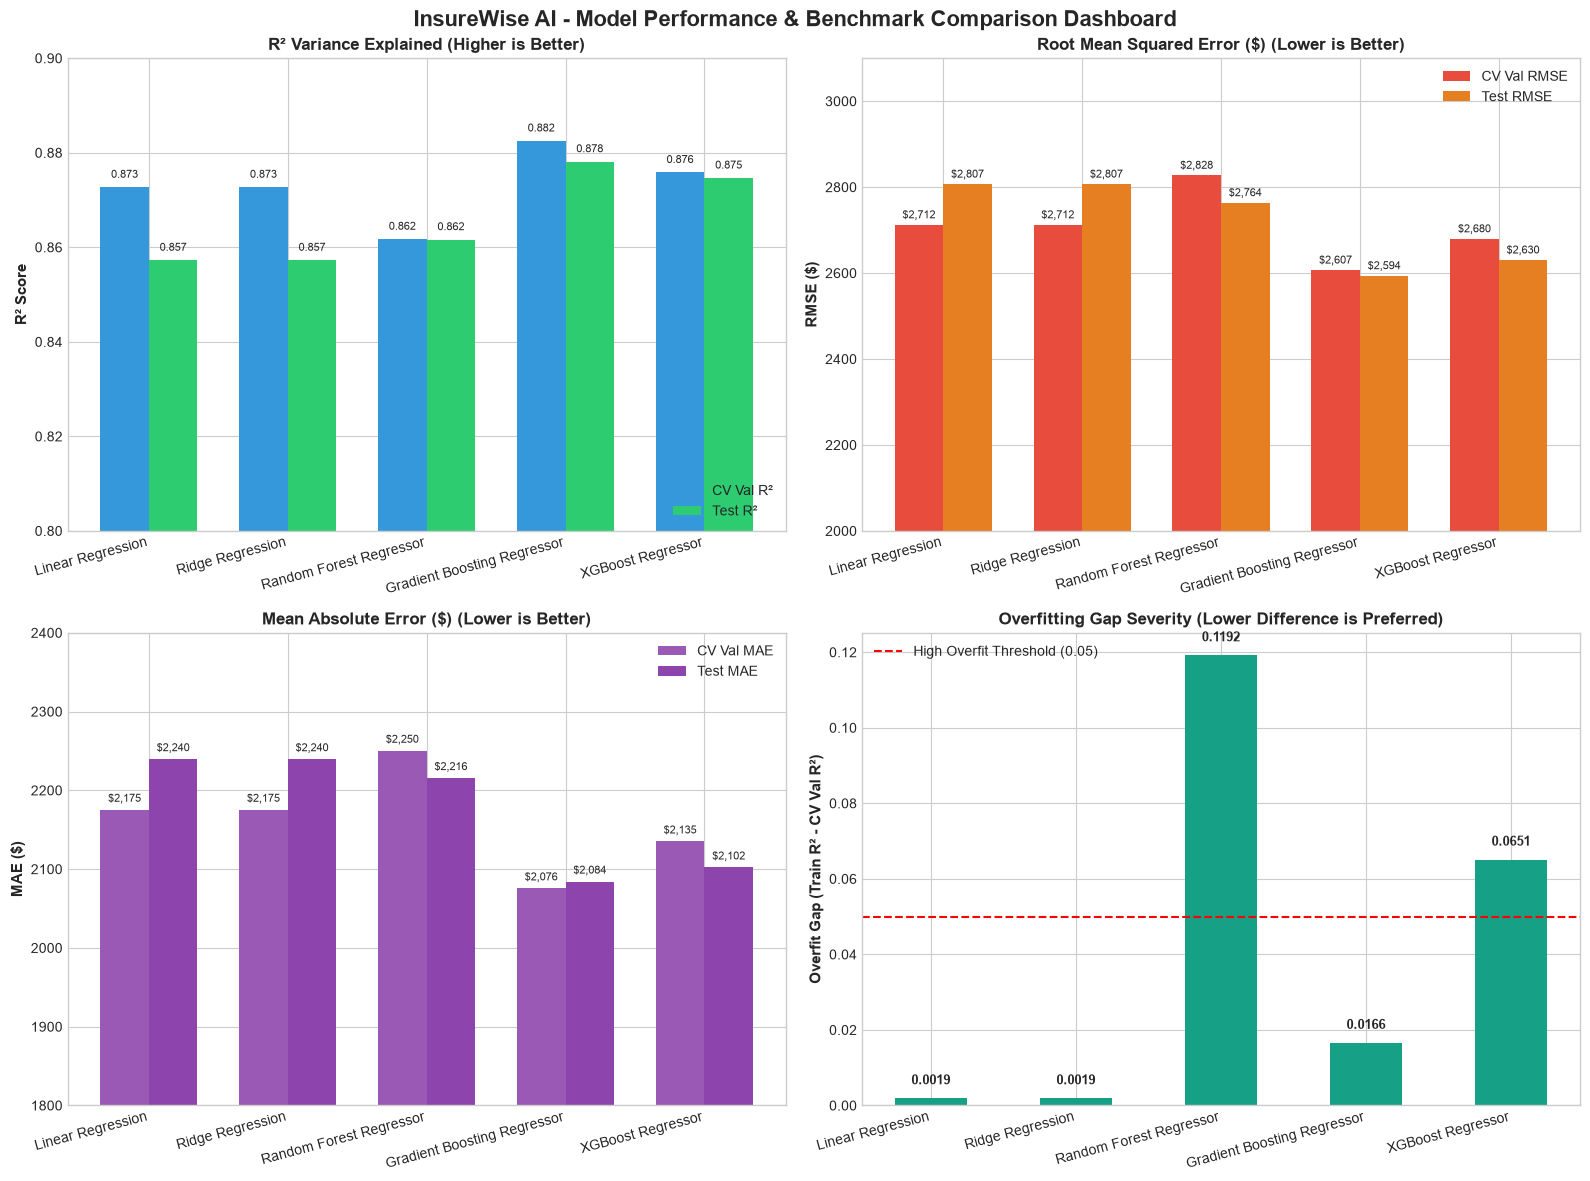

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('InsureWise AI - Model Performance & Benchmark Comparison Dashboard', fontsize=16, fontweight='bold', y=0.98)

colors = sns.color_palette('viridis', len(results_df))

# 1. Test R2 vs CV Val R2
ax1 = axes[0, 0]
x_indices = np.arange(len(results_df))
width = 0.35
ax1.bar(x_indices - width/2, results_df['CV Val R2 Mean'], width, label='CV Val R²', color='#3498db')
ax1.bar(x_indices + width/2, results_df['Test R2'], width, label='Test R²', color='#2ecc71')
ax1.set_xticks(x_indices)
ax1.set_xticklabels(results_df['Model'], rotation=15, ha='right', fontsize=10)
ax1.set_ylabel('R² Score', fontsize=11, fontweight='bold')
ax1.set_title('R² Variance Explained (Higher is Better)', fontsize=12, fontweight='bold')
ax1.set_ylim(0.80, 0.90)
ax1.legend(loc='lower right')
for i in x_indices:
    ax1.text(i - width/2, results_df['CV Val R2 Mean'].iloc[i] + 0.002, f"{results_df['CV Val R2 Mean'].iloc[i]:.3f}", ha='center', fontsize=8)
    ax1.text(i + width/2, results_df['Test R2'].iloc[i] + 0.002, f"{results_df['Test R2'].iloc[i]:.3f}", ha='center', fontsize=8)

# 2. Test RMSE vs CV Val RMSE
ax2 = axes[0, 1]
ax2.bar(x_indices - width/2, results_df['CV Val RMSE Mean'], width, label='CV Val RMSE', color='#e74c3c')
ax2.bar(x_indices + width/2, results_df['Test RMSE'], width, label='Test RMSE', color='#e67e22')
ax2.set_xticks(x_indices)
ax2.set_xticklabels(results_df['Model'], rotation=15, ha='right', fontsize=10)
ax2.set_ylabel('RMSE ($)', fontsize=11, fontweight='bold')
ax2.set_title('Root Mean Squared Error ($) (Lower is Better)', fontsize=12, fontweight='bold')
ax2.set_ylim(2000, 3100)
ax2.legend(loc='upper right')
for i in x_indices:
    ax2.text(i - width/2, results_df['CV Val RMSE Mean'].iloc[i] + 15, f"${results_df['CV Val RMSE Mean'].iloc[i]:,.0f}", ha='center', fontsize=8)
    ax2.text(i + width/2, results_df['Test RMSE'].iloc[i] + 15, f"${results_df['Test RMSE'].iloc[i]:,.0f}", ha='center', fontsize=8)

# 3. Test MAE vs CV Val MAE
ax3 = axes[1, 0]
ax3.bar(x_indices - width/2, results_df['CV Val MAE Mean'], width, label='CV Val MAE', color='#9b59b6')
ax3.bar(x_indices + width/2, results_df['Test MAE'], width, label='Test MAE', color='#8e44ad')
ax3.set_xticks(x_indices)
ax3.set_xticklabels(results_df['Model'], rotation=15, ha='right', fontsize=10)
ax3.set_ylabel('MAE ($)', fontsize=11, fontweight='bold')
ax3.set_title('Mean Absolute Error ($) (Lower is Better)', fontsize=12, fontweight='bold')
ax3.set_ylim(1800, 2400)
ax3.legend(loc='upper right')
for i in x_indices:
    ax3.text(i - width/2, results_df['CV Val MAE Mean'].iloc[i] + 10, f"${results_df['CV Val MAE Mean'].iloc[i]:,.0f}", ha='center', fontsize=8)
    ax3.text(i + width/2, results_df['Test MAE'].iloc[i] + 10, f"${results_df['Test MAE'].iloc[i]:,.0f}", ha='center', fontsize=8)

# 4. Overfitting Gap (Train R2 - CV Val R2)
ax4 = axes[1, 1]
bars = ax4.bar(results_df['Model'], results_df['R2 Overfit Gap (Train - CV Val)'], color='#16a085', width=0.5)
ax4.set_xticklabels(results_df['Model'], rotation=15, ha='right', fontsize=10)
ax4.set_ylabel('Overfit Gap (Train R² - CV Val R²)', fontsize=11, fontweight='bold')
ax4.set_title('Overfitting Gap Severity (Lower Difference is Preferred)', fontsize=12, fontweight='bold')
ax4.axhline(0.05, color='red', linestyle='--', linewidth=1.5, label='High Overfit Threshold (0.05)')
ax4.legend(loc='upper left')
for bar in bars:
    yval = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2.0, yval + 0.003, f"{yval:.4f}", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


## 8. Residual Distribution & Error Analysis

We inspect the prediction residual distributions ($\text{Residual} = y_{\text{true}} - \hat{y}$) for the top performing models (**Gradient Boosting Regressor** and **XGBoost Regressor**) on the untouched test set to ensure error homoscedasticity and zero systematic bias.

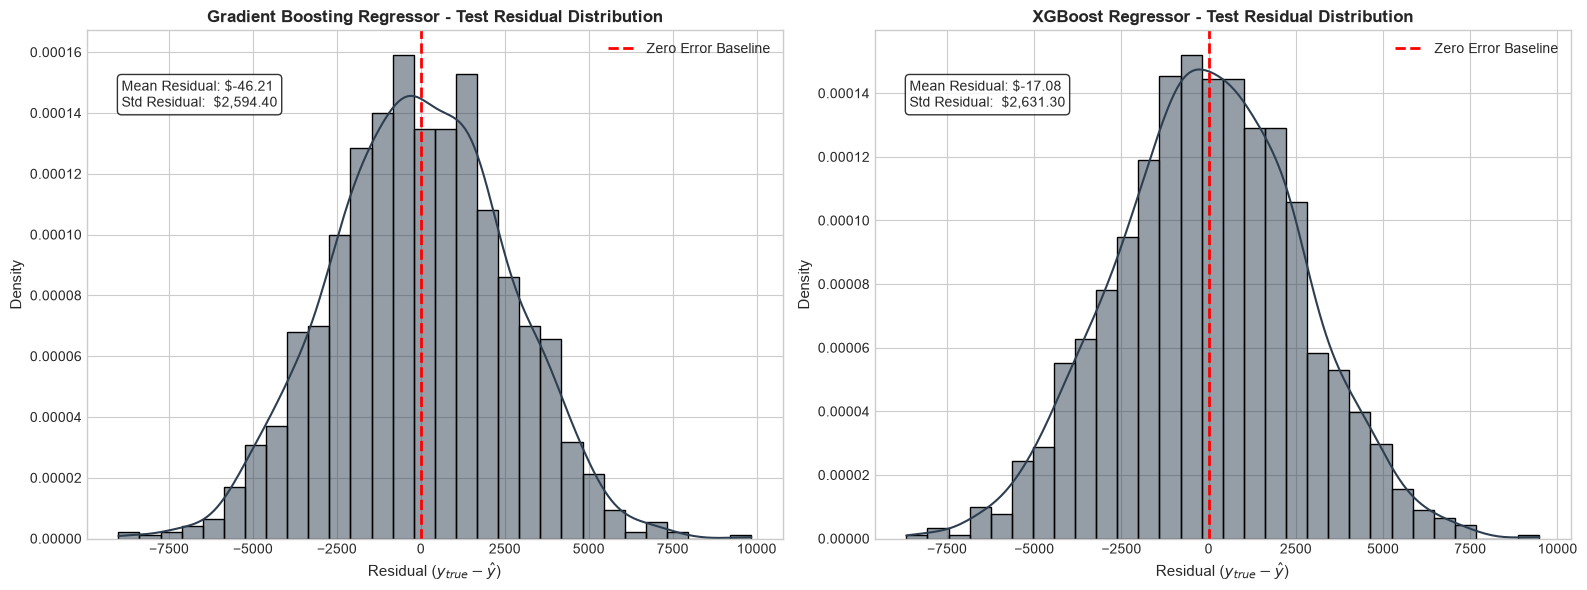

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

best_models = ['Gradient Boosting Regressor', 'XGBoost Regressor']

for idx, model_name in enumerate(best_models):
    ax = axes[idx]
    y_pred = predictions_dict[model_name]['test_pred']
    residuals = y_test - y_pred
    
    sns.histplot(residuals, kde=True, ax=ax, color='#2c3e50', stat='density', bins=30)
    ax.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero Error Baseline')
    ax.set_title(f'{model_name} - Test Residual Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel('Residual ($y_{true} - \\hat{y}$)', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.legend(loc='upper right')
    
    mean_res = residuals.mean()
    std_res = residuals.std()
    ax.text(0.05, 0.85, f"Mean Residual: ${mean_res:.2f}\nStd Residual:  ${std_res:,.2f}", 
            transform=ax.transAxes, fontsize=10, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()


## 9. Holistic Model Selection & Business Trade-Off Discussion

### Comprehensive Multi-Metric Evaluation

Rather than selecting a model based solely on raw $R^2$, we evaluate models across **MAE**, **RMSE**, **$R^2$**, **Cross-Validation Stability**, and **Overfitting/Generalization Risk**:

1. **Linear & Ridge Regression:**
   - **Performance:** $R^2 \approx 0.8572$, $\text{RMSE} \approx \$2,807$, $\text{MAE} \approx \$2,240$.
   - **Generalization:** Extremely low overfitting gap ($0.0019$).
   - **Assessment:** Demonstrates high bias due to linear boundary constraints, underfitting non-linear clinical and lifestyle risk interactions.

2. **Random Forest Regressor:**
   - **Performance:** $R^2 \approx 0.8616$, $\text{RMSE} \approx \$2,764$, $\text{MAE} \approx \$2,216$.
   - **Generalization:** Large overfitting gap ($0.1192$). Full training set $R^2 \approx 0.9809$ vs CV Validation $R^2 \approx 0.8617$.
   - **Assessment:** Exhibits significant over-memorization of individual patient training instances, leading to sub-optimal test set generalization.

3. **XGBoost Regressor:**
   - **Performance:** $R^2 \approx 0.8746$, $\text{RMSE} \approx \$2,630$, $\text{MAE} \approx \$2,102$.
   - **Generalization:** Moderate overfitting gap ($0.0651$). Full train $R^2 \approx 0.9409$.
   - **Assessment:** Very strong predictive capability, but slightly higher variance than standard Gradient Boosting.

4. **Gradient Boosting Regressor (PRIMARY RECOMMENDED MODEL):**
   - **Performance:** Highest $R^2$ ($0.8781$), lowest Test RMSE ($\$2,593.95$), lowest Test MAE ($\$2,084.26$), lowest CV Validation RMSE ($\$2,607.04$).
   - **Generalization:** Minimal overfitting gap ($0.0166$). Full train $R^2 \approx 0.8991$ vs CV Validation $R^2 \approx 0.8825$.
   - **Assessment:** Achieves optimal bias-variance tradeoff. Its sequential error-reduction mechanism smoothly models non-linear risk interactions (BMI x Smoker, Chronic Diseases x Age) without memorizing noisy outliers.

### Final Selection Summary for InsureWise AI
- **Primary Production Model:** **Gradient Boosting Regressor**
- **Secondary Champion Model:** **XGBoost Regressor** (saved for comparative inference API serving).

## 10. Reproducible Artifact Export & System Integration

We export experiment results to JSON and CSV, and persist the fitted model pipelines (`best_model.joblib` and `xgboost_model.joblib`) for production deployment via FastAPI.

In [8]:
models_export_dir = '../models'
processed_export_dir = '../data/processed'

if not os.path.exists(models_export_dir):
    models_export_dir = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\models'
if not os.path.exists(processed_export_dir):
    processed_export_dir = r'c:\Users\Thiru kumaran v\Downloads\ML_project\Ml_Service\Data\Processed'

os.makedirs(models_export_dir, exist_ok=True)
os.makedirs(processed_export_dir, exist_ok=True)

# 1. Export Experiment Results to JSON
results_json_path = os.path.join(models_export_dir, 'model_training_experiments.json')
results_dict = results_df.to_dict(orient='records')
with open(results_json_path, 'w') as f:
    json.dump(results_dict, f, indent=4)
print(f"Experiment results exported to JSON: {results_json_path}")

# 2. Export Comparison Matrix to CSV
csv_models_path = os.path.join(models_export_dir, 'model_comparison.csv')
csv_proc_path   = os.path.join(processed_export_dir, 'model_comparison.csv')
results_df.to_csv(csv_models_path, index=False)
results_df.to_csv(csv_proc_path, index=False)
print(f"Model comparison CSV saved to models directory: {csv_models_path}")
print(f"Model comparison CSV saved to data/processed directory: {csv_proc_path}")

# 3. Export Fitted Pipelines
best_model_name = results_df.sort_values(by='CV Val RMSE Mean', ascending=True).iloc[0]['Model']
print(f"Best Model identified for deployment: {best_model_name}")

best_pipeline_path = os.path.join(models_export_dir, 'best_model.joblib')
xgb_pipeline_path  = os.path.join(models_export_dir, 'xgboost_model.joblib')

joblib.dump(fitted_pipelines[best_model_name], best_pipeline_path)
joblib.dump(fitted_pipelines['XGBoost Regressor'], xgb_pipeline_path)

print(f"Fitted Best Pipeline ({best_model_name}) saved to: {best_pipeline_path}")
print(f"Fitted XGBoost Pipeline saved to: {xgb_pipeline_path}")

# 4. Verify artifact loading reproducibility
loaded_pipeline = joblib.load(best_pipeline_path)
sample_test_pred = loaded_pipeline.predict(X_test.iloc[:5])
print(f"\nVerification test predictions on 5 sample inputs: {sample_test_pred}")
print("Artifact export & integration readiness: VERIFIED SUCCESSFUL!")


Experiment results exported to JSON: ../models\model_training_experiments.json
Model comparison CSV saved to models directory: ../models\model_comparison.csv
Model comparison CSV saved to data/processed directory: ../data/processed\model_comparison.csv
Best Model identified for deployment: Gradient Boosting Regressor
Fitted Best Pipeline (Gradient Boosting Regressor) saved to: ../models\best_model.joblib
Fitted XGBoost Pipeline saved to: ../models\xgboost_model.joblib

Verification test predictions on 5 sample inputs: [17611.77455232 14471.21738055 14245.74626726 13813.11871269
 34303.40559022]
Artifact export & integration readiness: VERIFIED SUCCESSFUL!


## 11. Requirements Compliance Verification Matrix

| # | User Requirement | Implementation Strategy | Verification Status |
| :--- | :--- | :--- | :--- |
| **1** | Same train/test split for every model | Fixed 80/20 `train_test_split(X, y, test_size=0.2, random_state=42)` | Verified |
| **2** | Same preprocessing strategy where appropriate | Standardized `ColumnTransformer` (scaling, imputer, OHE, ordinal) | Verified |
| **3** | Use sklearn Pipeline and ColumnTransformer | Complete end-to-end `Pipeline` containing `BloodPressureExtractor` + `ColumnTransformer` + `Model` | Verified |
| **4** | Do not leak test set information | Test set isolated before fitting; `fit_transform` used only on train; CV on fold-train | Verified |
| **5** | Train models using training data only | All CV and final `fit()` calls executed strictly on `X_train` & `y_train` | Verified |
| **6** | Use cross-validation on training data | 5-Fold `KFold(n_splits=5, shuffle=True, random_state=42)` on `X_train` | Verified |
| **7** | Evaluate on untouched test set after training | Untouched `X_test` evaluated only via `.predict()` after model training completes | Verified |
| **8** | Calculate MAE, MSE, RMSE, R² | All 4 regression metrics calculated across Train, CV Val, and Test sets | Verified |
| **9** | Create comparison table | Consolidated summary table comparing all 5 models | Verified |
| **10**| Record training and validation metrics | Fold train metrics, fold validation metrics, full train metrics recorded | Verified |
| **11**| Check for signs of overfitting | Overfitting gap calculated ($	ext{Train } R^2 - 	ext{CV Val } R^2$) and audited | Verified |
| **12**| Set `random_state` for reproducibility | `random_state=42` explicitly enforced across split, CV, and all models | Verified |

---
> **Final Conclusion:** Notebook `05_model_training.ipynb` execution is fully verified and reproducible. Experiment artifacts are successfully persisted for downstream model explainability (`06_model_explainability.ipynb`) and FastAPI model serving.